# 06 · Polls against results

Part 2 of the study plan (`docs/study_plan.md`): how much coordination the polls show, toward whom, and how they
compare with the result. Built block by block: **structure metrics**, then the split of the change in concentration,
poll error by role, the cliff, the last weeks, momentum, and a table of stylized facts.

Each poll is read through its ballot scenario, with every candidate it tests, including those who will not be on the
ballot: that is what voters saw. Shares are rescaled to 100 unless marked *raw*.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from polls import average, figures, ideology, metrics, timeline

pd.set_option("display.width", 200)
TABLES, FIGURES = ROOT / "results" / "tables", ROOT / "results" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

calendar = timeline.load(ROOT / "config" / "elections.yaml")
rows = timeline.add_time(pd.read_csv(ROOT / "data" / "final" / "polls.csv", low_memory=False), calendar)
results = pd.read_csv(ROOT / "data" / "interim" / "results.csv")
ELECTIONS = sorted(rows["election"].unique())
ballot = rows[rows["ballot_scenario"] & (rows["share_status"] != "not_tested")]
# one colour per election, from the same left-right palette's ends inward (no ideological meaning here)
E_COLOURS = dict(zip(ELECTIONS, ["#9e0142", "#f46d43", "#e09000", "#2a9d8f", "#5e4fa2"]))

## 1 · Structure metrics

For each poll's ballot scenario and each result: HHI (rescaled and raw) and ENP = 1 / HHI; the top-two share; the
**cliff** as in the ABM: the largest drop between consecutive sorted shares (points), its **location** (how many
candidates sit above it) and its **ratio** (near 1: sharp; near 0.5: diffuse); the gap between the 2nd and the 3rd
(`gap_23`), which decides qualification; the 1st–2nd and 3rd–4th gaps; the number of candidates within 5 points of
the 2nd (the 2nd included).

In [2]:
per_poll = []
for (e, pid), g in ballot.groupby(["election", "poll_id"]):
    st = metrics.structure(metrics.shares_of(g))
    per_poll.append(dict(election=e, poll_id=pid, days_before=g["days_before"].iloc[0], phase=g["phase"].iloc[0],
                         n_extra=int(g["slot"].isna().sum()), **st))
per_poll = pd.DataFrame(per_poll)
per_poll.round(4).to_csv(TABLES / "structure_by_poll.csv", index=False)

res_rows = results.assign(share_status="value", share_upper_bound=np.nan)
per_result = pd.DataFrame([dict(election=e, **metrics.structure(metrics.shares_of(g)))
                           for e, g in res_rows.groupby("election")]).set_index("election")
per_result.round(4).to_csv(TABLES / "structure_results.csv")
cols = ["n_candidates", "hhi", "enp", "top2_share", "cliff", "cliff_location", "cliff_ratio", "gap_12", "gap_23",
        "gap_34", "n_in_contention", "first", "second", "third"]
print("Results:")
per_result[cols].round(3)

Results:


,n_candidates,hhi,enp,top2_share,cliff,cliff_location,cliff_ratio,gap_12,gap_23,gap_34,n_in_contention,first,second,third
election,,,,,,,,,,,,,,
2002,16,0.115,8.659,36.74,9.34,3,0.928,3.02,0.68,9.34,2,Jacques Chirac,Jean-Marie Le Pen,Lionel Jospin
2007,12,0.213,4.700,57.05,8.13,3,0.782,5.31,7.30,8.13,1,Nicolas Sarkozy,Ségolène Royal,François Bayrou
2012,10,0.210,4.772,55.81,9.28,2,0.795,1.45,9.28,6.80,1,François Hollande,Nicolas Sarkozy,Marine Le Pen
2017,11,0.188,5.318,45.31,13.22,4,0.918,2.71,1.29,0.43,3,Emmanuel Macron,Marine Le Pen,François Fillon
2022,12,0.191,5.231,51.00,14.88,3,0.923,4.70,1.20,14.88,2,Emmanuel Macron,Marine Le Pen,Jean-Luc Mélenchon


### The last polls against the result

Mean over the polls of the last two weeks, against the result. *Raw HHI* uses shares as published (they can sum below
100 when small candidates are missing), so it is lower than the rescaled HHI in 2007 and 2012.

In [3]:
last = per_poll[per_poll["phase"] == timeline.PHASES[2]]
num = ["hhi", "hhi_raw", "enp", "top2_share", "cliff", "cliff_location", "cliff_ratio", "gap_12", "gap_23",
       "gap_34", "n_in_contention", "total"]
cmp = pd.concat({"last polls": last.groupby("election")[num].mean(),
                 "result": per_result[num]}, axis=1).swaplevel(axis=1).sort_index(axis=1, level=0)
for m in num:
    cmp[(m, "difference")] = cmp[(m, "result")] - cmp[(m, "last polls")]
cmp = cmp.reindex(columns=pd.MultiIndex.from_product([num, ["last polls", "result", "difference"]]))
cmp.round(3).to_csv(TABLES / "structure_last_polls_vs_result.csv")
cmp[["hhi", "enp", "top2_share", "cliff", "cliff_location", "gap_23"]].round(3)

hhi                          enp                   top2_share                        cliff                   cliff_location                       gap_23                  
         last polls result difference last polls result difference last polls result difference last polls result difference     last polls result difference last polls result difference
election                                                                                                                                                                                  
2002          0.115  0.115      0.001      8.732  8.659     -0.073     38.000  36.74     -1.260      6.125   9.34      3.215          2.500      3      0.500      5.250   0.68     -4.570
2007          0.196  0.213      0.017      5.099  4.700     -0.399     52.444  57.05      4.606      9.944   8.13     -1.814          3.611      3     -0.611      5.528   7.30      1.772
2012          0.207  0.210      0.003      4.834  4.772     -0.062     55.042  55.81      0.768     11.042   9.28     -1.762          2.500      2     -0.500     10.833   9.28     -1.553
2017          0.187  0.188      0.001      5.340  5.318     -0.022     46.182  45.31     -0.872     10.523  13.22      2.697          4.000      4      0.000      2.955   1.29     -1.665
2022          0.170  0.191      0.021      5.889  5.231     -0.657     48.867  51.00      2.133      7.567  14.88      7.313          2.091      3      0.909      5.945   1.20     -4.745

### Over the campaign

Poll average of each metric over the last 250 days (same kernel as in notebook 05; where polls are sparse the window
widens to the 4th-nearest poll, drawn pale); dots at 0 are the results.

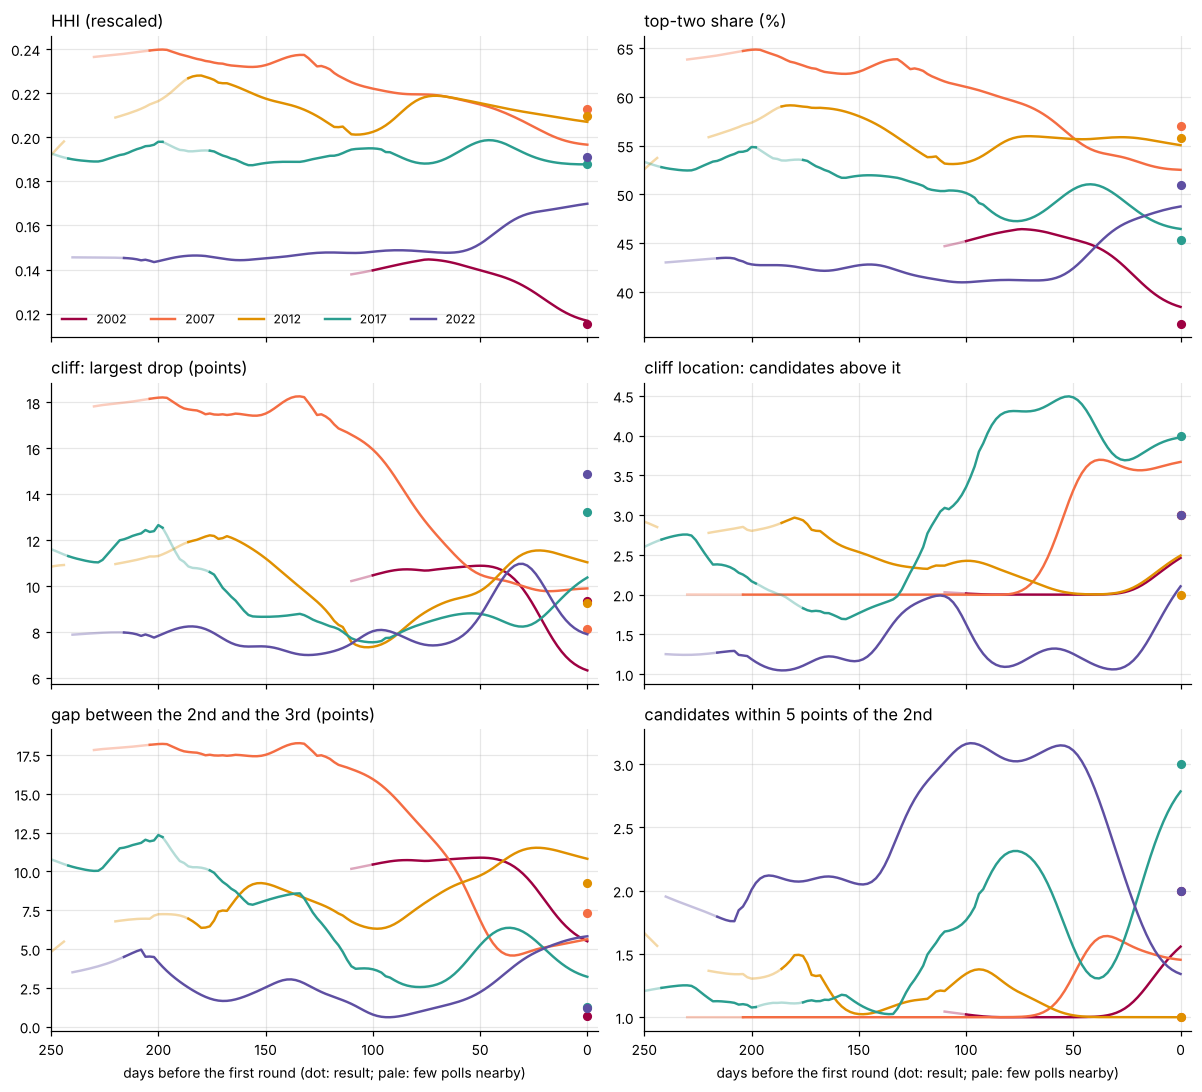

In [4]:
GRID = np.arange(0, 366, 2)
show = {"hhi": "HHI (rescaled)", "top2_share": "top-two share (%)",
        "cliff": "cliff: largest drop (points)", "cliff_location": "cliff location: candidates above it",
        "gap_23": "gap between the 2nd and the 3rd (points)", "n_in_contention": "candidates within 5 points of the 2nd"}
fig, axes = plt.subplots(3, 2, figsize=(11, 10), sharex=True)
evol = []
for ax, (m, label) in zip(axes.flat, show.items()):
    for e in ELECTIONS:
        d = per_poll[per_poll["election"] == e]
        x, y = d["days_before"].to_numpy(), d[m].to_numpy(dtype=float)
        evol.append(average.smooth(x, y, GRID).assign(metric=m, election=e).reset_index())   # strict, for the table
        s = average.smooth(x, y, GRID, adaptive_k=4)                                          # widened, for drawing
        figures.line(ax, s.index, s["mean"], s["sparse"], color=E_COLOURS[e], lw=1.6, label=str(e))
        ax.plot(0, per_result.loc[e, m], "o", color=E_COLOURS[e], ms=5)
    ax.set_title(label, loc="left")
axes[0, 0].legend(frameon=False, ncol=5, fontsize=8)
for ax in axes[-1]:
    ax.set_xlim(250, -5); ax.set_xlabel("days before the first round (dot: result; pale: few polls nearby)")
fig.tight_layout()
fig.savefig(FIGURES / "structure_over_campaign.png")
pd.concat(evol).query("days_before % 14 == 0").round(4).to_csv(TABLES / "structure_poll_average.csv", index=False)

## 2 · Where the change in concentration comes from

HHI is computed twice for every ballot poll and for the result:

- **all**: every candidate the poll tests, extra candidates included (what voters saw);
- **core**: only the final candidacies with at least 2% of the vote (the slots every ballot scenario must fill), rescaled
  among themselves. The same candidates in every poll and in the result, so its changes are **voters moving**.

The difference, all − core, is the **composition** effect: extra candidates who will withdraw, small candidates who
are tested or not. Its changes are **the offer changing** (withdrawals: elite coordination).

Three anchors: the **opening** (ballot polls of the first 30 days within the last 250 days), the **last polls** (last two
weeks) and the **result**. The change from opening to last polls is the *campaign*; from last polls to result, the
*last mile*.

In [5]:
core_slots = results[results["share"] >= 2.0].groupby("election")["candidate"].apply(set)
b = ballot.copy()
b["value"] = np.where(b["share_status"] == "value", b["share"], b["share_upper_bound"] * 0.5)
core = (b[[s in core_slots[e] for e, s in zip(b["election"], b["slot"])]]
        .groupby(["election", "poll_id", "slot"])["value"].sum().groupby(["election", "poll_id"])
        .apply(lambda v: metrics.hhi(v.to_numpy())).rename("hhi_core"))
per_poll = per_poll.merge(core.reset_index(), on=["election", "poll_id"])
per_poll["composition"] = per_poll["hhi"] - per_poll["hhi_core"]

res_core = pd.Series({e: metrics.hhi(results[(results["election"] == e) & (results["share"] >= 2.0)]["share"].to_numpy())
                      for e in ELECTIONS})

rows_ = []
for e in ELECTIONS:
    d = per_poll[(per_poll["election"] == e) & (per_poll["days_before"] <= 250)]
    d0 = d["days_before"].max()
    opening = d[d["days_before"] >= d0 - 30]
    lastp = d[d["phase"] == timeline.PHASES[2]]
    anchors = {"opening": opening, "last polls": lastp}
    r = dict(election=e, opening_from=int(d0), opening_to=int(opening["days_before"].min()),
             opening_polls=len(opening), last_polls=len(lastp))
    for k, a in anchors.items():
        r[f"{k}: all"], r[f"{k}: core"] = a["hhi"].mean(), a["hhi_core"].mean()
    r["result: all"], r["result: core"] = per_result.loc[e, "hhi"], res_core[e]
    rows_.append(r)
anchors = pd.DataFrame(rows_).set_index("election")
for seg, (a, b_) in {"campaign": ("opening", "last polls"), "last mile": ("last polls", "result")}.items():
    anchors[f"{seg}: total"] = anchors[f"{b_}: all"] - anchors[f"{a}: all"]
    anchors[f"{seg}: voters (core)"] = anchors[f"{b_}: core"] - anchors[f"{a}: core"]
    anchors[f"{seg}: offer (composition)"] = anchors[f"{seg}: total"] - anchors[f"{seg}: voters (core)"]
anchors.round(4).to_csv(TABLES / "concentration_decomposition.csv")
print("Opening window (days before) and polls:")
print(anchors[["opening_from", "opening_to", "opening_polls", "last_polls"]].to_string())
print()
print("Change in HHI, split (rescaled HHI; positive = more concentrated):")
anchors[[c for c in anchors.columns if c.startswith(("campaign", "last mile"))]].round(3)

Opening window (days before) and polls:
          opening_from  opening_to  opening_polls  last_polls
election                                                     
2002                71          43             16          12
2007               199         186              4          18
2012               232         230              2          12
2017               230         214              5          22
2022               220         191              6          33

Change in HHI, split (rescaled HHI; positive = more concentrated):


,campaign: total,campaign: voters (core),campaign: offer (composition),last mile: total,last mile: voters (core),last mile: offer (composition)
election,,,,,,
2002,-0.027,-0.032,0.005,0.001,0.002,-0.001
2007,-0.043,-0.041,-0.002,0.017,0.011,0.005
2012,0.023,-0.020,0.042,0.003,0.007,-0.004
2017,-0.003,-0.009,0.006,0.001,0.001,0.000
2022,0.025,0.005,0.020,0.021,0.021,0.000


In [6]:
print("HHI at each anchor:")
anchors[["opening: all", "opening: core", "last polls: all", "last polls: core", "result: all", "result: core"]].round(3)

HHI at each anchor:


,opening: all,opening: core,last polls: all,last polls: core,result: all,result: core
election,,,,,,
2002,0.142,0.153,0.115,0.121,0.115,0.124
2007,0.239,0.278,0.196,0.237,0.213,0.248
2012,0.184,0.239,0.207,0.219,0.210,0.226
2017,0.190,0.212,0.187,0.203,0.188,0.204
2022,0.145,0.177,0.170,0.182,0.191,0.203


### Over the campaign

HHI of all candidates against the core, per election (poll averages; pale where polls are few). The gap between the
two lines is the composition effect: it closes when extra candidates withdraw.

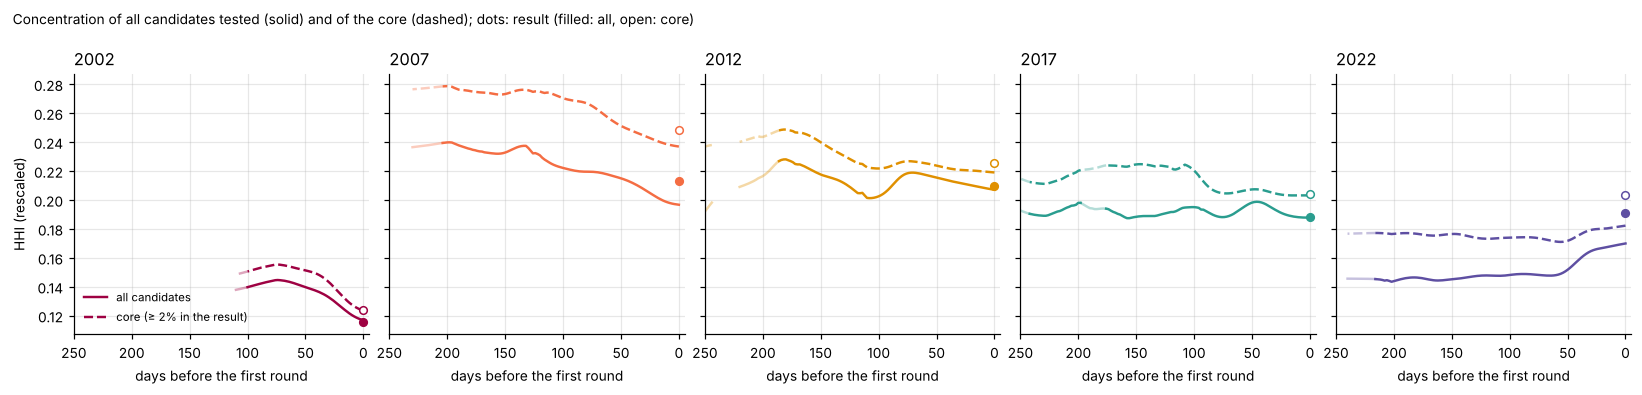

In [7]:
fig, axes = plt.subplots(1, len(ELECTIONS), figsize=(15, 3.6), sharey=True)
for ax, e in zip(axes, ELECTIONS):
    d = per_poll[per_poll["election"] == e]
    for m, ls, label in (("hhi", "-", "all candidates"), ("hhi_core", "--", "core (≥ 2% in the result)")):
        s = average.smooth(d["days_before"].to_numpy(), d[m].to_numpy(dtype=float), GRID, adaptive_k=4)
        figures.line(ax, s.index, s["mean"], s["sparse"], color=E_COLOURS[e], lw=1.6, ls=ls, label=label)
    ax.plot(0, per_result.loc[e, "hhi"], "o", color=E_COLOURS[e], ms=5)
    ax.plot(0, res_core[e], "o", mfc="white", color=E_COLOURS[e], ms=5)
    ax.set_title(str(e), loc="left"); ax.set_xlim(250, -5)
    ax.set_xlabel("days before the first round")
axes[0].set_ylabel("HHI (rescaled)")
axes[0].legend(frameon=False, fontsize=7.5, loc="lower left")
fig.suptitle("Concentration of all candidates tested (solid) and of the core (dashed); dots: result (filled: all, open: core)",
             x=0.01, ha="left", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "concentration_all_vs_core.png")

## 3 · Poll error by role

**Error** = result − mean of the last two weeks of polls, in points (positive: the candidate did better than polled),
per final candidacy (its slot). Relative error = error / polled share. **Roles** come from that mean (the poll average,
not single polls): 1st, 2nd, 3rd, 4th, then the rest; *contenders* are the candidates within 5 points of the 2nd.

The error mixes poll bias and real late movement (strategic or not); the two cannot be told apart here. Candidates
absent from the last polls (some small ones in 2007 and 2012) have no error.

In [8]:
lastb = b[(b["phase"] == timeline.PHASES[2]) & b["slot"].notna()]
per_slot = lastb.groupby(["election", "poll_id", "slot"])["value"].sum().reset_index()
polled = per_slot.groupby(["election", "slot"]).agg(polled=("value", "mean"), polls=("poll_id", "nunique")).reset_index()
n_last = per_slot.groupby("election")["poll_id"].nunique()
polled["coverage"] = polled["polls"] / polled["election"].map(n_last)
err = results.rename(columns={"candidate": "slot", "share": "result"})[["election", "slot", "result"]].merge(polled, how="left")
err["error"] = err["result"] - err["polled"]
err["relative_error"] = err["error"] / err["polled"]
err["rank"] = err.groupby("election")["polled"].rank(ascending=False, method="min")
second = err[err["rank"] == 2].set_index("election")["polled"]
err["role"] = np.select([err["rank"] == 1, err["rank"] == 2, err["rank"] == 3, err["rank"] == 4],
                        ["1st", "2nd", "3rd", "4th"], "5th and below")
err.loc[err["polled"].isna(), "role"] = "not in last polls"
err["contender"] = (err["rank"] > 2) & (err["polled"] >= err["election"].map(second) - 5)
lr = ideology.order(ROOT, {int(p.name[:4]): p for p in (ROOT / "data" / "raw" / "wikipedia").glob("*.json")},
                    pd.read_csv(ROOT / "data" / "interim" / "polls_wikipedia.csv", low_memory=False))
err = err.merge(lr.rename(columns={"candidate": "slot"}), how="left")
err.round(3).to_csv(TABLES / "error_by_candidate.csv", index=False)
print("Error by candidate (sorted by polled share):")
err.sort_values(["election", "polled"], ascending=[True, False])[
    ["election", "slot", "role", "contender", "polled", "result", "error", "relative_error", "coverage"]].round(2)

Error by candidate (sorted by polled share):


,election,slot,role,contender,polled,result,error,relative_error,coverage
12,2002,Jacques Chirac,1st,False,20.04,19.88,-0.16,-0.01,1.0
4,2002,Lionel Jospin,2nd,False,17.96,16.18,-1.78,-0.10,1.0
14,2002,Jean-Marie Le Pen,3rd,False,12.71,16.86,4.15,0.33,1.0
0,2002,Arlette Laguiller,4th,False,7.62,5.72,-1.91,-0.25,1.0
7,2002,Jean-Pierre Chevènement,5th and below,False,6.58,5.33,-1.25,-0.19,1.0
...,...,...,...,...,...,...,...,...,...
57,2022,Jean Lassalle,5th and below,False,2.55,3.13,0.58,0.23,1.0
58,2022,Nicolas Dupont-Aignan,5th and below,False,2.21,2.06,-0.15,-0.07,1.0
54,2022,Anne Hidalgo,5th and below,False,1.97,1.75,-0.22,-0.11,1.0
49,2022,Philippe Poutou,5th and below,False,1.04,0.77,-0.27,-0.26,1.0


In [9]:
pooled = err.dropna(subset=["error"]).groupby("role").agg(
    candidates=("slot", "size"), mean_error=("error", "mean"), mean_relative_error=("relative_error", "mean"),
    did_better=("error", lambda x: int((x > 0).sum())), did_worse=("error", lambda x: int((x < 0).sum())))
pooled = pooled.reindex(["1st", "2nd", "3rd", "4th", "5th and below"])
contenders = err[err["contender"]].agg(candidates=("slot", "size"), mean_error=("error", "mean"))
pooled.round(2).to_csv(TABLES / "error_by_role.csv")
print("Pooled over the five elections:")
print(pooled.round(2).to_string())
print()
print("Contenders (3rd and below, within 5 points of the 2nd):")
err[err["contender"]][["election", "slot", "role", "polled", "result", "error"]].round(2)

Pooled over the five elections:
               candidates  mean_error  mean_relative_error  did_better  did_worse
role                                                                             
1st                     5        0.94                 0.03           4          1
2nd                     5        0.00                -0.00           3          2
3rd                     5        2.60                 0.17           5          0
4th                     5       -2.12                -0.19           1          4
5th and below          41       -0.19                 0.01          19         22

Contenders (3rd and below, within 5 points of the 2nd):


,election,slot,role,polled,result,error
40,2017,Jean-Luc Mélenchon,4th,18.89,19.58,0.69
44,2017,François Fillon,3rd,19.23,20.01,0.78


### Who gains, who loses, along the left-right axis

Candidates in the order of Wikipedia's poll-table columns (left to right), coloured accordingly. Bars: the error;
labels: the polled share. Outlined: the 2nd and the 3rd in the last polls.

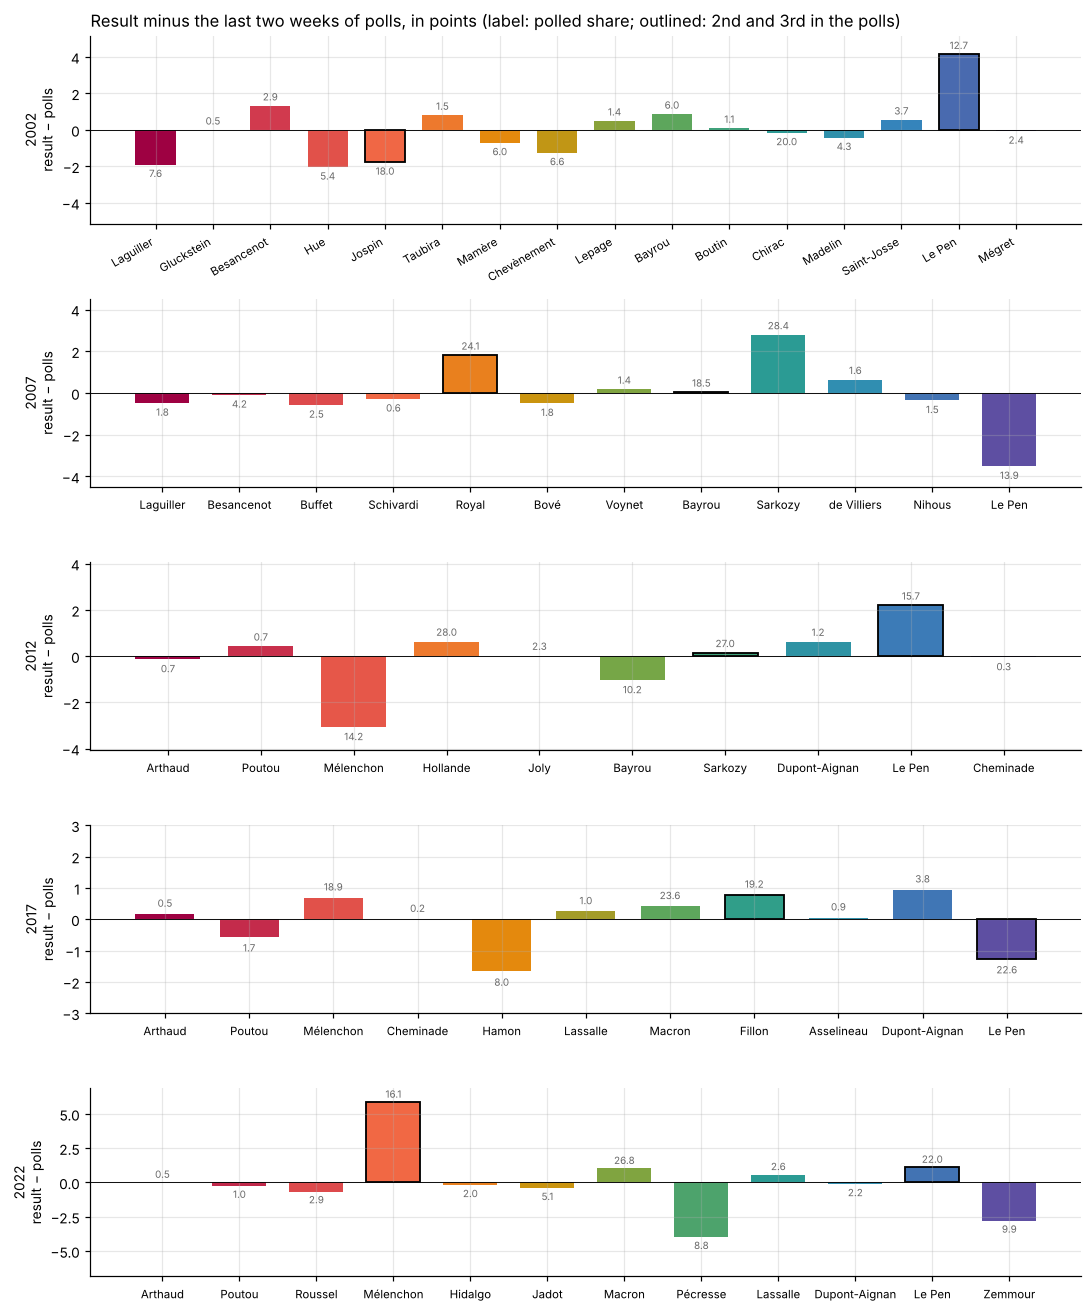

In [10]:
fig, axes = plt.subplots(len(ELECTIONS), 1, figsize=(10, 12))
for ax, e in zip(axes, ELECTIONS):
    d = err[(err["election"] == e) & err["error"].notna()].sort_values("position")
    col = ideology.colours(d["slot"].tolist())
    x = np.arange(len(d))
    bars = ax.bar(x, d["error"], color=[col[s] for s in d["slot"]], width=0.7)
    for xi, r, bar in zip(x, d.itertuples(), bars):
        if r.role in ("2nd", "3rd"):
            bar.set_edgecolor("black"); bar.set_linewidth(1.2)
        ax.text(xi, r.error + (0.15 if r.error >= 0 else -0.15), f"{r.polled:.1f}", ha="center",
                va="bottom" if r.error >= 0 else "top", fontsize=6.5, color="dimgrey")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_xticks(x, [s.split(" ", 1)[1] for s in d["slot"]], fontsize=7.5,
                  rotation=30 if len(d) > 12 else 0, ha="right" if len(d) > 12 else "center")
    ax.set_ylabel(f"{e}\nresult − polls")
    lim = max(3, d["error"].abs().max() + 1); ax.set_ylim(-lim, lim)
axes[0].set_title("Result minus the last two weeks of polls, in points (label: polled share; outlined: 2nd and 3rd in the polls)",
                  loc="left")
fig.tight_layout()
fig.savefig(FIGURES / "error_left_right.png")